# Description: 
Real Estate Valuation Pipeline: Combines econometric OLS modeling, VIF multicollinearity diagnostics, and Lasso regularization with Random Forest ensembles to predict and explain property pricing across 19,000+ housing records.

# Module 1: Data Setup & Stratified Train-Test Split
We load the dataset and perform a stratified split using a binned version of house prices to ensure the price distribution remains balanced across training and testing sets.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Load dataset
houses = pd.read_csv('version_D.csv')

# Separate target and features
y = houses.price
X = houses.drop(['price', 'price_hilo'], axis=1)

# Stratified split based on binned house prices
y_binned = pd.qcut(y, q=100)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=617, train_size=0.7, stratify=y_binned
)

# Module 2: Exploratory Data Analysis & Feature Insights
We inspect feature distributions and filter subsets to extract targeted market trends (e.g., analyzing neighborhood dynamics and lot sizes).

In [2]:
# Summary statistics for training features
X_train.describe(include='all')

# Filter subset: Neighborhood 1 with at least 2 bedrooms
filtered_houses = X_train[(X_train['bedrooms'] >= 2) & (X_train['neighborhood'] == 1)]
avg_distance = filtered_houses['distance_city'].mean()
print(f"Average distance to city for filtered homes: {avg_distance:.2f} miles")

# Median lot size analysis by bedroom count
median_lot_by_bedrooms = X_train.groupby('bedrooms')['lot_size'].median()
largest_lot_bedrooms = median_lot_by_bedrooms.idxmax()
print(f"Houses with {largest_lot_bedrooms} bedrooms have the largest median lot size.")

Average distance to city for filtered homes: 6.43 miles
Houses with 1 bedrooms have the largest median lot size.


## VISUALIZATION: Area vs. Price 

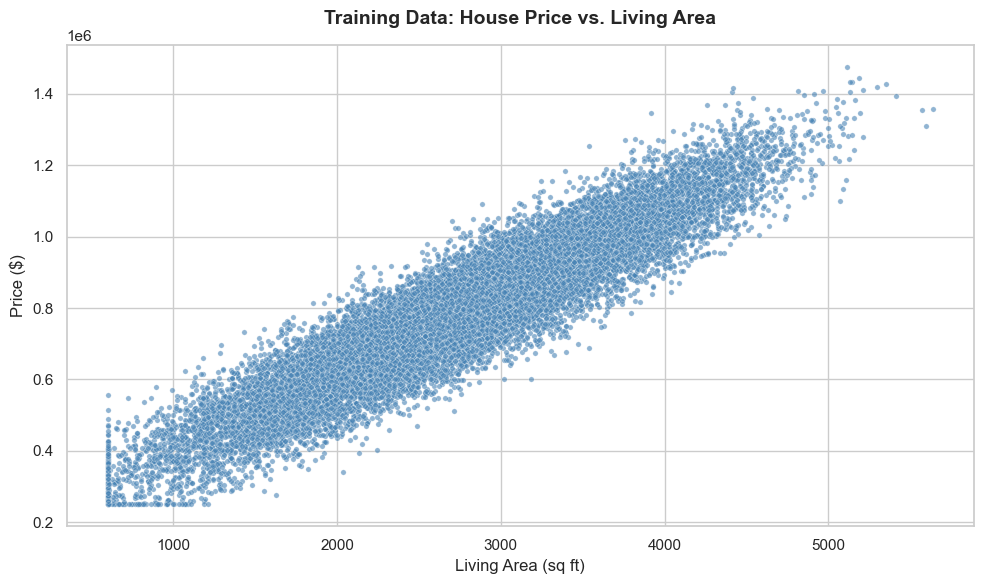

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reconstruct training and testing dataframes with price for visualization
train = X_train.assign(price=y_train)
test = X_test.assign(price=y_test)

# Set clean aesthetic style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Generate scatter plot of square footage vs. house price
sns.scatterplot(
    data=train, 
    x='area', 
    y='price', 
    color='steelblue', 
    alpha=0.6,
    s=15
)

# Add professional labels and title
plt.title('Training Data: House Price vs. Living Area', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Living Area (sq ft)', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

# Module 3: Econometric OLS Regression & Multicollinearity (VIF)
We fit multiple OLS models using statsmodels to evaluate pricing drivers, test polynomial/quadratic effects, and check for multicollinearity using Variance Inflation Factors (VIF).

In [9]:
from statsmodels.formula.api import ols
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.api import add_constant

# 1. Full Linear OLS Model
reg = ols('price ~ bedrooms + bathrooms + area + lot_size + floors + age + garage + fireplace + renovated + neighborhood + distance_city', data=train)
model = reg.fit()
print(model.summary())

# 2. Multicollinearity Check (VIF)
vif_data = pd.DataFrame()
vif_data['Variable'] = X_train.columns
vif_data['VIF'] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
print(vif_data.sort_values('VIF', ascending=False))

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                 3.057e+04
Date:                Mon, 12 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:40:30   Log-Likelihood:            -2.3374e+05
No. Observations:               19110   AIC:                         4.675e+05
Df Residuals:                   19098   BIC:                         4.676e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       1.02e+05   2553.556     39.931

# Module 4: Machine Learning Ensembles & Decision Trees
We move beyond linear assumptions by implementing Decision Trees, Bagging Regressors, and Random Forests to capture non-linear relationships and interactions.

In [10]:
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error
import numpy as np

# Random Forest Model Implementation
forest = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=617, n_jobs=-1)
forest.fit(X_train, y_train)

pred_train = forest.predict(X_train)
pred_test = forest.predict(X_test)

print(f"Random Forest Train RMSE: {root_mean_squared_error(y_train, pred_train):.2f}")
print(f"Random Forest Test RMSE: {root_mean_squared_error(y_test, pred_test):.2f}")

# Feature Importance Ranking
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': forest.feature_importances_
}).sort_values('Importance', ascending=False)
print(importance_df)

/opt/anaconda3/envs/pred_env/lib/python3.13/site-packages/sklearn/ensemble/_forest.py:513: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  y_type = type_of_target(y)


Random Forest Train RMSE: 19965.11
Random Forest Test RMSE: 53353.57
          Feature  Importance
2            area    0.882163
9    neighborhood    0.045191
3        lot_size    0.025779
10  distance_city    0.021994
5             age    0.010649
1       bathrooms    0.003966
0        bedrooms    0.002578
6          garage    0.002140
4          floors    0.001962
8       renovated    0.001930
7       fireplace    0.001647


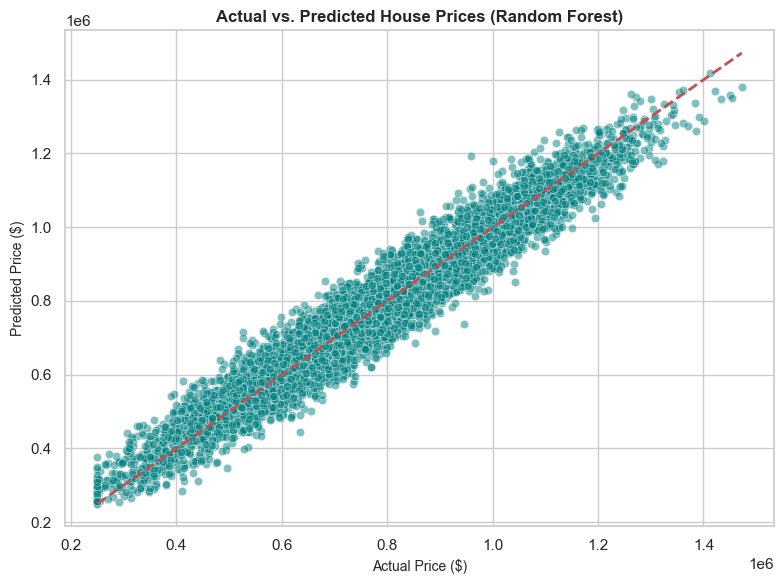

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizing Actual vs Predicted Prices on the Test Set
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=pred_test, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
plt.title('Actual vs. Predicted House Prices (Random Forest)', fontsize=12, fontweight='bold')
plt.xlabel('Actual Price ($)', fontsize=10)
plt.ylabel('Predicted Price ($)', fontsize=10)
plt.tight_layout()
plt.show()

# Module 5: Binary Classification (High/Low Pricing)
We evaluate a classification target (price_hilo) using Logistic Regression to predict premium property tiers.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Setup classification target
y_class = houses.price_hilo
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X, y_class, train_size=0.7, random_state=617, stratify=y_class
)

# Fit Logistic Regression for classification
log_model = LogisticRegression(max_iter=10000, random_state=617)
log_model.fit(X_class_train, y_class_train)

# Evaluate ROC-AUC
y_train_prob = log_model.predict_proba(X_class_train)[:, 1]
train_auc = roc_auc_score(y_class_train, y_train_prob)
print(f"Area under the ROC curve (Train sample): {train_auc:.4f}")

Area under the ROC curve (Train sample): 0.9847
